# Sanity checks against known facts (step 0.35)

Before trusting any situation effect, the marts should reproduce numbers already published elsewhere. If the league's home record or scoring were off, every split built on them would be suspect.

This notebook computes, for every regular season from 1999 to 2025:
- the home teams' win % and average margin;
- points per game, per team and per game (both teams).

It then checks them against published figures.

**Games, not team-games.** `marts.team_games` has two rows per game, one per team. Taking only the home team's row gives exactly one row per game. Its points for and against are the two teams' scores, so nothing is counted twice.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))

from pipeline.analysis import FIRST_SEASON, LAST_SEASON, SERIES, TEXT_SECONDARY, chart_style, read_mart, regular_season, save_figure

chart_style()
team_games = regular_season(read_mart("team_games"))
print(f"{len(team_games):,} team-games = {team_games['game_id'].nunique():,} games, {FIRST_SEASON}–{LAST_SEASON} regular seasons")

13,934 team-games = 6,967 games, 1999–2025 regular seasons


## Two definitions of "home"

- **`is_home`: the designated home team.** It's the team listed second in the schedule, even at a neutral site such as a London game. Published league records ("home teams went 127–128–1") use this one.
- **`venue = 'home'`: the team really at its own stadium.** It's what the site's venue split uses. A designated home team at a neutral site counts as `neutral`.

The two differ only in neutral-site games. Both are computed below.

**Win %** = (wins + ½ × ties) / games, the NFL standings definition. A tie counts as half a win.

In [2]:
def season_summary(home_rows: pd.DataFrame) -> pd.DataFrame:
    """Per season, from one row per game (the home side's): record, win %, average margin, scoring."""
    by_season = home_rows.groupby("season")
    summary = pd.DataFrame(
        {
            "games": by_season.size(),
            "wins": by_season["result"].apply(lambda r: (r == "win").sum()),
            "losses": by_season["result"].apply(lambda r: (r == "loss").sum()),
            "ties": by_season["result"].apply(lambda r: (r == "tie").sum()),
            "avg_margin": by_season["margin"].mean(),
            "total_points": by_season["points_for"].sum() + by_season["points_against"].sum(),
        }
    )
    summary["win_pct"] = (summary["wins"] + summary["ties"] / 2) / summary["games"]
    summary["points_per_game"] = summary["total_points"] / summary["games"]  # both teams
    summary["points_per_team_game"] = summary["points_per_game"] / 2
    return summary


designated = season_summary(team_games[team_games["is_home"]])
at_home = season_summary(team_games[team_games["venue"] == "home"])

designated.round(3)

,games,wins,losses,ties,avg_margin,total_points,win_pct,points_per_game,points_per_team_game
season,,,,,,,,,
1999,248,148,100,0,3.065,10324.0,0.597,41.629,20.815
2000,248,138,110,0,2.823,10254.0,0.556,41.347,20.673
2001,248,136,112,0,2.008,10024.0,0.548,40.419,20.210
2002,256,148,107,1,2.246,11097.0,0.580,43.348,21.674
2003,256,157,99,0,3.555,10666.0,0.613,41.664,20.832
2004,256,145,111,0,2.508,11000.0,0.566,42.969,21.484
2005,256,151,105,0,3.648,10556.0,0.590,41.234,20.617
2006,256,136,120,0,0.848,10577.0,0.531,41.316,20.658
2007,256,147,109,0,2.867,11104.0,0.574,43.375,21.688


## Home win % and margin by season

The home team's average margin is the home edge in points. Each season is about 256–272 games, so a single season's win % carries roughly ±3 percentage points of luck. Single-season dips are noise until they repeat.

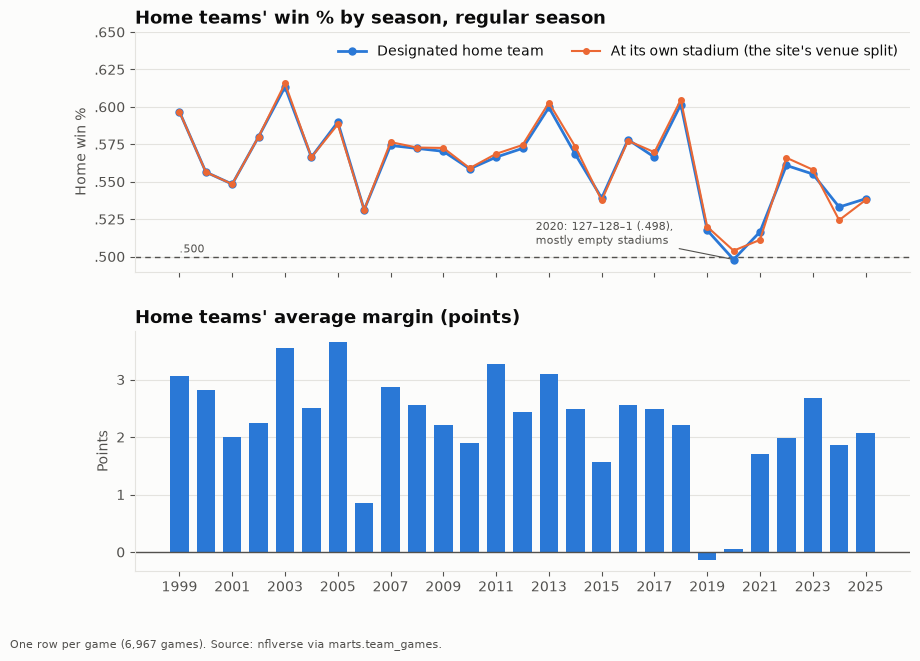

In [3]:
fig, (ax_pct, ax_margin) = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw={"hspace": 0.25})
seasons = designated.index

ax_pct.axhline(0.5, color=TEXT_SECONDARY, linewidth=1, linestyle=(0, (4, 3)))
ax_pct.plot(seasons, designated["win_pct"], color=SERIES[0], marker="o", markersize=5, label="Designated home team")
ax_pct.plot(seasons, at_home["win_pct"], color=SERIES[1], marker="o", markersize=4, linewidth=1.5, label="At its own stadium (the site's venue split)")
ax_pct.annotate(".500", (seasons.min(), 0.5), xytext=(0, 3), textcoords="offset points", color=TEXT_SECONDARY, fontsize=8)
ax_pct.annotate("2020: 127–128–1 (.498),\nmostly empty stadiums", (2020, designated.loc[2020, "win_pct"]), xytext=(2012.5, 0.506),
                ha="left", va="bottom", color=TEXT_SECONDARY, fontsize=8, arrowprops={"arrowstyle": "-", "color": TEXT_SECONDARY, "linewidth": 0.8})
ax_pct.set_title("Home teams' win % by season, regular season")
ax_pct.set_ylabel("Home win %")
ax_pct.yaxis.set_major_formatter(lambda y, _: f"{y:.3f}".lstrip("0"))
ax_pct.set_ylim(0.49, 0.65)
ax_pct.legend(loc="upper right", ncols=2)

ax_margin.axhline(0, color=TEXT_SECONDARY, linewidth=1)
ax_margin.bar(seasons, designated["avg_margin"], color=SERIES[0], width=0.7)
ax_margin.set_title("Home teams' average margin (points)")
ax_margin.set_ylabel("Points")
ax_margin.set_xticks(range(FIRST_SEASON, LAST_SEASON + 1, 2))
fig.text(0.0, 0.0, f"One row per game ({designated['games'].sum():,} games). Source: nflverse via marts.team_games.", color=TEXT_SECONDARY, fontsize=8)

save_figure(fig, "home_win_pct_by_season")
plt.show()

## Points per game by season

Scoring is shown per team-game, the figure the league and the press quote ("24.8 points per team in 2020").

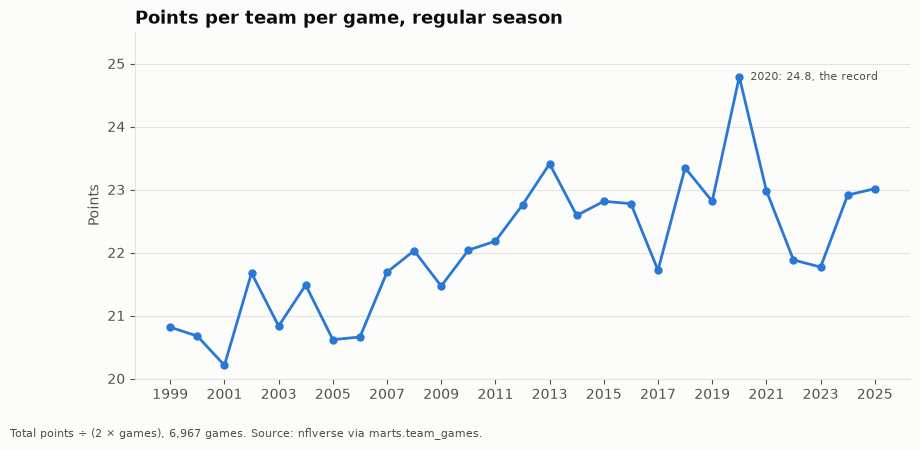

In [4]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(designated.index, designated["points_per_team_game"], color=SERIES[0], marker="o", markersize=5)
peak = designated["points_per_team_game"].idxmax()
ax.annotate(f"{peak}: {designated.loc[peak, 'points_per_team_game']:.1f}, the record", (peak, designated.loc[peak, "points_per_team_game"]),
            xytext=(8, 0), textcoords="offset points", ha="left", va="center", color=TEXT_SECONDARY, fontsize=8)
ax.set_ylim(20, 25.5)
ax.set_title("Points per team per game, regular season")
ax.set_ylabel("Points")
ax.set_xticks(range(FIRST_SEASON, LAST_SEASON + 1, 2))
fig.text(0.0, -0.02, f"Total points ÷ (2 × games), {designated['games'].sum():,} games. Source: nflverse via marts.team_games.", color=TEXT_SECONDARY, fontsize=8)

save_figure(fig, "points_per_game_by_season")
plt.show()

## Against published figures

Published sources quote the designated home team's record and scoring to one decimal place. Each value is compared at the precision it was published with.

| Figure | Source |
| ------ | ------ |
| Home teams 132–123–1 in 2019, 127–128–1 in 2020 | [NBC Sports / ProFootballTalk](https://www.nbcsports.com/nfl/profootballtalk/rumor-mill/news/home-field-was-no-advantage-home-teams-went-127-128-1-in-2020-season) |
| 24.8 points per team in 2020, the previous high 23.4 in 2013; 12,692 points in 2020 | Associated Press, via [Yahoo Sports](https://sports.yahoo.com/nfl-had-highest-scoring-season-095912718.html) |
| Games averaged 49.6 points in 2020, 46.0 in 2021, 43.8 in 2022, 43.5 in 2023 | [Boston Globe](https://www.bostonglobe.com/2024/03/30/sports/sunday-football-notes-nfl-scoring/) |

Pro Football Reference's league-averages table was the first choice, but it refuses automated requests (a bot check), so these news sources stand in.

In [5]:
def record(season: int, summary: pd.DataFrame = designated) -> str:
    """A season's record as wins–losses–ties."""
    wins, losses, ties = summary.loc[season, ["wins", "losses", "ties"]].astype(int)
    return f"{wins}–{losses}–{ties}"


published = pd.DataFrame(
    [
        ("Home record 2019", "132–123–1", record(2019)),
        ("Home record 2020", "127–128–1", record(2020)),
        ("Points per team-game 2013", "23.4", f"{designated.loc[2013, 'points_per_team_game']:.1f}"),
        ("Points per team-game 2020", "24.8", f"{designated.loc[2020, 'points_per_team_game']:.1f}"),
        ("Total points 2020", "12692", f"{designated.loc[2020, 'total_points']:.0f}"),
        ("Points per game 2020", "49.6", f"{designated.loc[2020, 'points_per_game']:.1f}"),
        ("Points per game 2021", "46.0", f"{designated.loc[2021, 'points_per_game']:.1f}"),
        ("Points per game 2022", "43.8", f"{designated.loc[2022, 'points_per_game']:.1f}"),
        ("Points per game 2023", "43.5", f"{designated.loc[2023, 'points_per_game']:.1f}"),
    ],
    columns=["figure", "published", "ours"],
)
published["match"] = published["published"] == published["ours"]
published

,figure,published,ours,match
0,Home record 2019,132–123–1,132–123–1,True
1,Home record 2020,127–128–1,127–128–1,True
2,Points per team-game 2013,23.4,23.4,True
3,Points per team-game 2020,24.8,24.8,True
4,Total points 2020,12692,12692,True
5,Points per game 2020,49.6,49.6,True
6,Points per game 2021,46.0,46.0,True
7,Points per game 2022,43.8,43.8,True
8,Points per game 2023,43.5,43.5,True


## The site's venue split, reconciled

`venue = 'home'` shows 2020 at .504, not .498. The difference is the 49ers' three Glendale "home" games (weeks 13, 14 and 17, all losses). They were moved to Arizona by Santa Clara County's COVID rules, and nflverse lists them as neutral-site games. Adding them back gives the published record exactly. (`docs/data-model.md`, `mart_league_splits`, explains the same reconciliation.)

In [6]:
sf_glendale = team_games[(team_games["season"] == 2020) & team_games["is_home"] & (team_games["venue"] == "neutral")]
print(sf_glendale[["game_id", "team", "result", "points_for", "points_against"]].to_string(index=False))
print(f"\nvenue = 'home', 2020: {at_home.loc[2020, 'wins']}–{at_home.loc[2020, 'losses']}–{at_home.loc[2020, 'ties']} in {at_home.loc[2020, 'games']} games ({at_home.loc[2020, 'win_pct']:.3f})")
print(f"plus the Glendale games: {record(2020)} in {designated.loc[2020, 'games']} ({designated.loc[2020, 'win_pct']:.3f})")

       game_id team result  points_for  points_against
2020_13_BUF_SF   SF   loss        24.0            34.0
2020_14_WAS_SF   SF   loss        15.0            23.0
2020_17_SEA_SF   SF   loss        23.0            26.0

venue = 'home', 2020: 127–125–1 in 253 games (0.504)
plus the Glendale games: 127–128–1 in 256 (0.498)


## The mart agrees

The site will read `mart_league_splits`, which stores sums and counts per season and situation value. Its `venue = home` rows must give the same record and points as the row-level calculation above.

In [7]:
league = read_mart("mart_league_splits", "situation_key = 'venue' AND situation_value = 'home' AND season_type = 'REG' AND season BETWEEN :first AND :last",
                   {"first": FIRST_SEASON, "last": LAST_SEASON}).set_index("season").sort_index()
mart_vs_rows = pd.DataFrame(
    {
        "games": league["games"] - at_home["games"],
        "wins": league["wins"] - at_home["wins"],
        "ties": league["ties"] - at_home["ties"],
        "points": league["points_for"] + league["points_against"] - at_home["total_points"],
    }
)
print("Largest difference between the mart and the rows, per column:")
mart_vs_rows.abs().max()

Largest difference between the mart and the rows, per column:


games     0.0
wins      0.0
ties      0.0
points    0.0
dtype: float64

## Done-when check

The plan asks for numbers that match published figures, e.g. home teams finishing below .500 in 2020.

In [8]:
assert published["match"].all(), published[~published["match"]]
assert record(2020) == "127–128–1" and designated.loc[2020, "win_pct"] < 0.5
assert len(sf_glendale) == 3 and (sf_glendale["result"] == "loss").all()
assert (mart_vs_rows == 0).all().all()
assert (designated["win_pct"] < 0.5).sum() == 1  # 2020 is the only losing home season in the range
for name in ["home_win_pct_by_season", "points_per_game_by_season"]:
    assert (ROOT / "docs" / "figures" / f"{name}.png").exists()
print(f"All {len(published)} published figures match; 2020 home teams finished {record(2020)} ({designated.loc[2020, 'win_pct']:.3f}), the only season below .500.")

All 9 published figures match; 2020 home teams finished 127–128–1 (0.498), the only season below .500.
